# Group Comparison - Six Individual Models

Run this notebook **after all six member notebooks finish**. It reads their saved hold-out metrics, ranks the models, and saves a comparison table, charts and a prediction file for `test.csv`. Each member tuned settings on training-only 5-fold cross-validation; the 20 % hold-out split of `train.csv` was used once for the final comparison. Choosing the single winner from the hold-out results makes the winner's score slightly optimistic, so treat it as a comparison on this dataset, not a guarantee for new data.

## How to interpret the comparison

The target is the sale price in dollars. **RMSLE** (error on the log price) is the main ranking metric: it measures *relative* error, so a $20k miss on a cheap house counts more than on a mansion. **RMSE** and **MAE** are in dollars; **R²** is the share of price variance explained. Compare the cross-validation RMSLE with the hold-out RMSLE: a large gap would be a generalisation warning.

## 1. Find the project and load all six result files

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path.cwd(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "data/raw/train.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the extracted project.")
RESULTS = PROJECT_ROOT / "results" / "individual_models"
member_ids = ["MEMBER1", "MEMBER2", "MEMBER3", "MEMBER4", "MEMBER5", "MEMBER6"]
files = [RESULTS / member / "test_metrics.csv" for member in member_ids]
missing = [str(p) for p in files if not p.exists()]
if missing:
    raise FileNotFoundError("Run the six individual notebooks first. Missing results:\n" + "\n".join(missing))
results = pd.concat([pd.read_csv(p) for p in files], ignore_index=True)
results = results.sort_values("holdout_rmsle").reset_index(drop=True)
display(results[["member_id", "model", "selected_preprocessing", "best_cv_rmsle", "holdout_rmsle",
                 "rmse", "mae", "r2"]].round(4))

,member_id,model,selected_preprocessing,best_cv_rmsle,holdout_rmsle,rmse,mae,r2
0,MEMBER4,Support Vector Regression,StandardScaler,0.1083,0.1286,22148.4090,13972.4130,0.9360
1,MEMBER1,Ridge Regression,StandardScaler,0.1111,0.1295,22014.1364,14764.1835,0.9368
2,MEMBER6,Histogram Gradient Boosting,StandardScaler,0.1196,0.1319,24673.6075,15101.9195,0.9206
3,MEMBER3,Random Forest,StandardScaler,0.1374,0.1449,28437.8842,16965.6376,0.8946
4,MEMBER5,K-Nearest Neighbors,StandardScaler,0.1619,0.1820,38842.6901,21648.2975,0.8033
5,MEMBER2,Decision Tree,MinMaxScaler,0.1877,0.1912,37784.8359,24286.9605,0.8139


## 2. Compare and identify the top hold-out result

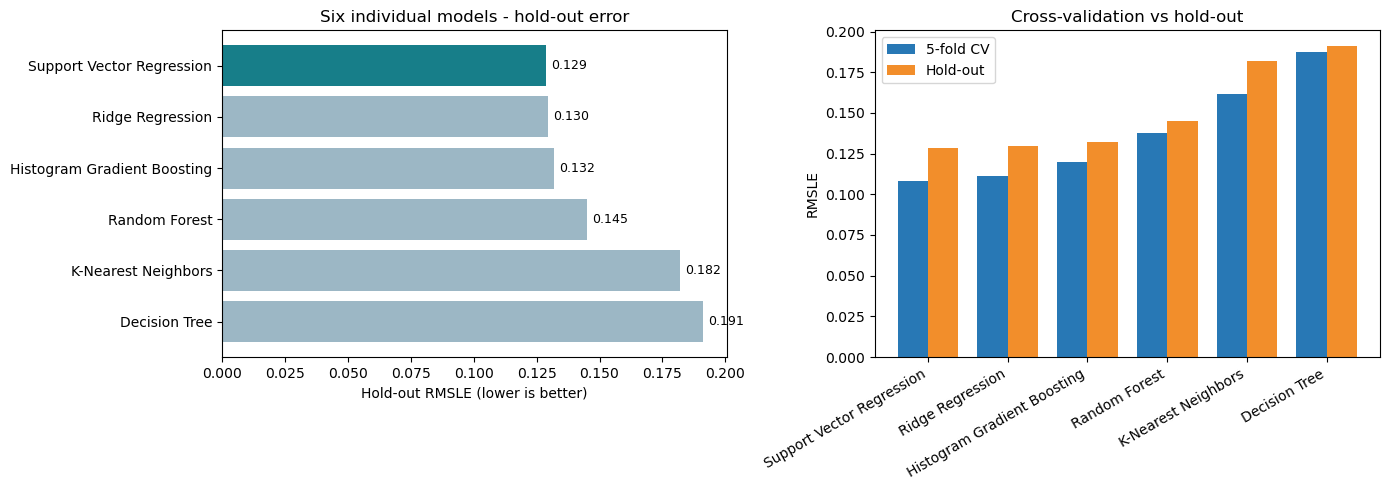

Lowest hold-out RMSLE: Support Vector Regression (MEMBER4)
RMSLE=0.1286; RMSE=$22,148; MAE=$13,972; R2=0.9360
Saved group comparison to: six_model_comparison


In [2]:
OUTPUT = PROJECT_ROOT / "results" / "six_model_comparison"
OUTPUT.mkdir(parents=True, exist_ok=True)
results.to_csv(OUTPUT / "six_model_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#177E89" if i == 0 else "#9CB7C5" for i in range(len(results))]
axes[0].barh(results["model"][::-1], results["holdout_rmsle"][::-1], color=colors[::-1])
axes[0].set_xlabel("Hold-out RMSLE (lower is better)"); axes[0].set_title("Six individual models - hold-out error")
for y, v in enumerate(results["holdout_rmsle"][::-1]):
    axes[0].text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=9)

x = range(len(results)); w = 0.38
axes[1].bar([i - w / 2 for i in x], results["best_cv_rmsle"], w, label="5-fold CV", color="#2878B5")
axes[1].bar([i + w / 2 for i in x], results["holdout_rmsle"], w, label="Hold-out", color="#F28E2B")
axes[1].set_xticks(list(x)); axes[1].set_xticklabels(results["model"], rotation=30, ha="right")
axes[1].set_ylabel("RMSLE"); axes[1].set_title("Cross-validation vs hold-out"); axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT / "six_model_rmsle.png", dpi=160)
plt.show()

best = results.iloc[0]
print(f"Lowest hold-out RMSLE: {best['model']} ({best['member_id']})")
print(f"RMSLE={best['holdout_rmsle']:.4f}; RMSE=${best['rmse']:,.0f}; MAE=${best['mae']:,.0f}; R2={best['r2']:.4f}")
print("Saved group comparison to:", OUTPUT.name)

## 3. Predictions for test.csv from the best model

`test.csv` has no `SalePrice`, so this file can only be scored by whoever holds the true prices (e.g. an instructor or Kaggle).

In [3]:
pred_file = RESULTS / best["member_id"] / "test_predictions.csv"
submission = pd.read_csv(pred_file)
(PROJECT_ROOT / "results" / "outputs").mkdir(parents=True, exist_ok=True)
submission.to_csv(PROJECT_ROOT / "results" / "outputs" / "submission_best_model.csv", index=False)
print("Best model:", best["model"], "| rows:", len(submission))
submission.round(0).head()

Best model: Support Vector Regression | rows: 1459


,Id,SalePrice
0,1461,116549.0
1,1462,157984.0
2,1463,183689.0
3,1464,199222.0
4,1465,187050.0


## Group conclusion prompt

In your viva, name the model with the lowest hold-out RMSLE, then compare its RMSE/MAE in dollars and R² with the others, and explain how much the tree/boosting models improve on the linear baseline (Ridge) and why. Explain each member's selected scaler and hyperparameters, and state the limits: one 80/20 split of 1,460 houses from one city (Ames, Iowa, 2006-2010), a winner picked on the same hold-out set it is reported on, and no way to score `test.csv` locally.